In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
import pickle
pd.set_option('display.max_columns', None)

Ytest = pd.read_csv('data/processed/internal_Ytest.csv',index_col=0)
Ypros = pd.read_csv('data/processed/temporal_Y.csv',index_col=0)
Y_bwh = pd.read_csv('data/processed/external_bwh_Y.csv',index_col=0)
Y_bwh = Y_bwh.iloc[:,1:]
AEnames = Y_bwh.columns.tolist()

In [85]:
bwh = {}
with open('results/shap/external_bwh/lumped_value_series.pkl', 'rb') as file: 
    bwh['lumped_value_series'] = pickle.load(file)
with open('results/shap/external_bwh/shap_values_dfs.pkl', 'rb') as file: 
    bwh['shap_values_dfs'] = pickle.load(file)
# with open('results/shap/external_bwh/explainer_ext_dict.pkl', 'rb') as file:
#     bwh['explainer_ext_dict'] = pickle.load(file)

retro = {}
with open('results/shap/internal/lumped_value_series.pkl', 'rb') as file: 
    retro['lumped_value_series'] = pickle.load(file)
with open('results/shap/internal/shap_values_dfs.pkl', 'rb') as file: 
    retro['shap_values_dfs'] = pickle.load(file)
# with open('results/shap/internal/explainer_ext_dict.pkl', 'rb') as file:
#     retro['explainer_ext_dict'] = pickle.load(file)

pro = {}
with open('results/shap/temporal/lumped_value_series.pkl', 'rb') as file: 
    pro['lumped_value_series'] = pickle.load(file)
with open('results/shap/temporal/shap_values_dfs.pkl', 'rb') as file: 
    pro['shap_values_dfs'] = pickle.load(file)


In [86]:
bwh['shap_values_dfs']['mortality'].shape

(4000, 438)

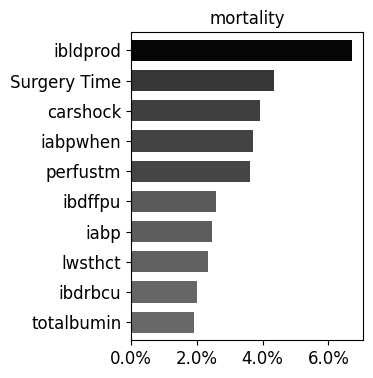

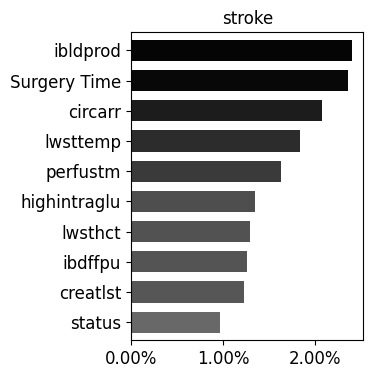

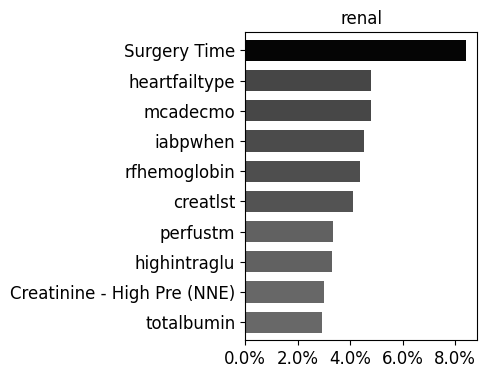

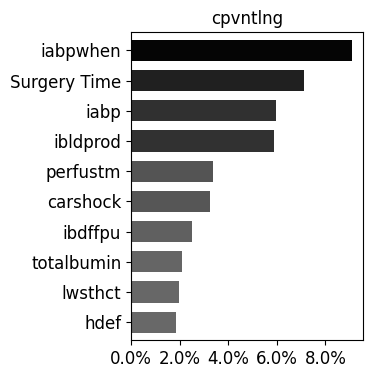

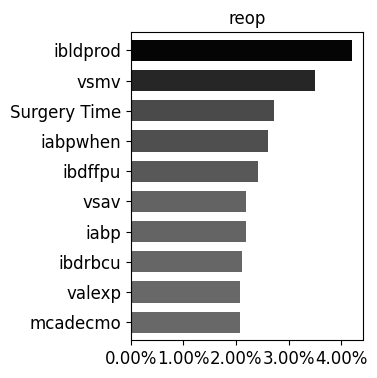

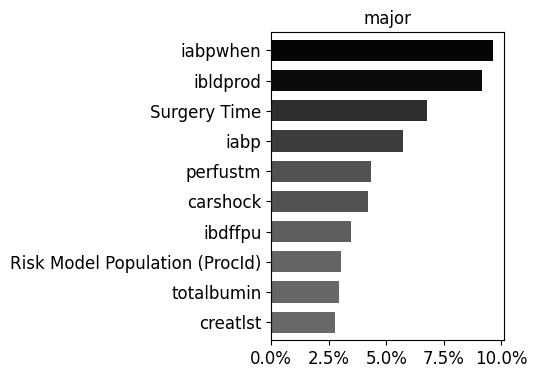

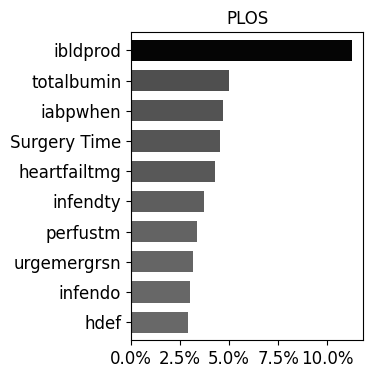

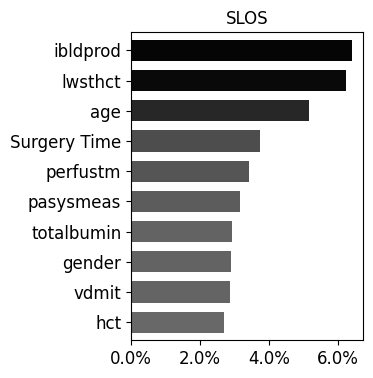

In [87]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter

# Creating a custom colormap from orange to yellow
colors = ["#686868","#050505"]  # RGB for orange and yellow
n_bins = 100  # Discretize into 100 steps
cmap_name = 'orange_yellow'
cm = LinearSegmentedColormap.from_list(cmap_name, colors, N=n_bins)

savepath = 'outputs/figure4/summary_shap'
for AE in AEnames:
    plt.figure(figsize=(3, 4))  # Set the size of the plot
    tmp = (retro['lumped_value_series'][AE] + pro['lumped_value_series'][AE] + bwh['lumped_value_series'][AE])/3
    tmp = tmp.sort_values(ascending=True)
    tmp = tmp[-10:]
    norm = plt.Normalize(tmp.min(), tmp.max())
    colors = cm(norm(tmp.values))
    
    ax = tmp.plot(kind='barh',width=0.7,color=colors)#'#e28645')
    plt.title(AE)
    # plt.xlabel('sum of total absolute shap value')
    # Setting font size for the tick labels
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    # ax.set_xticks([])
    # plt.tight_layout()
    plt.savefig(savepath+'/'+AE+'sumSHAP.jpg', format='jpg', dpi=300,bbox_inches='tight')
    # plt.show()

In [88]:
Ytest = pd.read_csv('data/processed/internal_Ytest.csv',index_col=0)
Ypros = pd.read_csv('data/processed/temporal_Y.csv',index_col=0)
Y_bwh = pd.read_csv('data/processed/external_bwh_Y.csv',index_col=0)
Y_bwh = Y_bwh.iloc[:,1:]

Xtest = pd.read_csv('data/processed/internal_Xtest.csv',index_col=0)
Xtest = Xtest.reset_index(drop=True)
Xpros = pd.read_csv('data/processed/temporal_X.csv',index_col=0)
Xpros = Xpros.reset_index(drop=True)
# X_bwh = pd.read_csv('data/processed/external_bwh_X.csv',index_col=0)
# X_bwh['Surgery Time'] = X_bwh['Surgery Time']/60
X_bwh = pd.read_csv('data/processed/external_bwh_X_4k_sample.csv',index_col=0)
X_bwh = X_bwh.reset_index(drop=True)

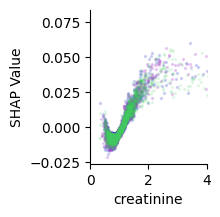

In [183]:
AE = 'major'
savepath = 'outputs/figure4/dependence_plots'

# var = 'Surgery Time'
# var = 'perfustm'
# var = 'ibdffpu'
# var = 'totalbumin'
var = 'creatlst'

fig, ax = plt.subplots(figsize=(1.5, 2))
# shap_values_test_ext = shap_values_dfs[AE]
plt.scatter(Xtest[var],retro['shap_values_dfs'][AE][var],s=2,color="#4051D0BE", alpha=0.2)
plt.scatter(Xpros[var],pro['shap_values_dfs'][AE][var],s=2,color="#AA40D0BD", alpha=0.2)
plt.scatter(X_bwh[var],bwh['shap_values_dfs'][AE][var],s=2,color="#40D05FBC", alpha=0.1)
# plt.xticks([0,2.5,5])
plt.xlim([0,4])
# plt.grid()
plt.xlabel('creatinine')
plt.ylabel('SHAP Value')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.savefig(savepath+'/'+AE+'_'+var+'.jpg', format='jpg', dpi=300,bbox_inches='tight')


/var/folders/d1/3bngkt6j06z8c88jx3kxc22w0000gn/T/ipykernel_53063/2702013955.py:27: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[var] = X.idxmax(axis=1).str.replace(var+'_', '')#.value_counts()
/var/folders/d1/3bngkt6j06z8c88jx3kxc22w0000gn/T/ipykernel_53063/2702013955.py:38: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[var] = X.idxmax(axis=1).str.replace(var+'_', '')#.value_counts()
/var/folders/d1/3bngkt6j06z8c88jx3kxc22w0000gn/T/ipykernel_53063/2702013955.py:49: SettingWithCopyWarning: 
A value is t

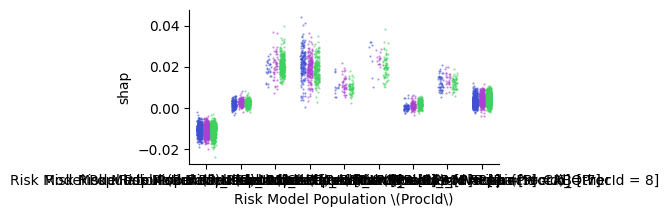

In [202]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(4, 2))
savepath = 'outputs/figure4/dependence_plots'
AE = 'major'

var = 'Risk Model Population \(ProcId\)'

order = ['No', 'Yes']
order = ['missing', 'No', 'Yes']
order = ['missing', 'Preop', 'Intraop']
order = ['missing', 'No', 'Yes']
order = ['Risk Model Population (ProcId)_Isolated CAB [ProcId = 1]',
         'Risk Model Population (ProcId)_Isolated AVR [ProcId = 2]',
         'Risk Model Population (ProcId)_Isolated MVR [ProcId = 3]',
         'Risk Model Population (ProcId)_AVR + CAB [ProcId = 4]',
         'Risk Model Population (ProcId)_MVR + CAB [ProcId = 5]',
         'Risk Model Population (ProcId)_AVR + MVR [ProcId = 6]',
         'Risk Model Population (ProcId)_MV Repair [ProcId = 7]',
         'Risk Model Population (ProcId)_MV Repair + CAB [ProcId = 8]',
         'Risk Model Population (ProcId)_Other']

collections = []

X = Xtest.filter(regex=var+'_')
var_embedded = X.columns.tolist()

X[var] = X.idxmax(axis=1).str.replace(var+'_', '')#.value_counts()
X = X.reset_index(drop=True)
X['shap'] = retro['shap_values_dfs'][AE][var_embedded].sum(axis=1)
X = X[X[var].isin(order)]  # Filter out unwanted values
strip1 = sns.stripplot(data=X, x=var, y='shap', jitter=0.07,color="#4051D0BE", 
                       alpha=0.6, size=1.5, ax=ax,order = order)
for i in range(len(order)):
    collections.append(strip1.collections[-(i+1)])

X = Xpros.filter(regex=var+'_')
var_embedded = X.columns.tolist()
X[var] = X.idxmax(axis=1).str.replace(var+'_', '')#.value_counts()
X = X.reset_index(drop=True)
X['shap'] = pro['shap_values_dfs'][AE][var_embedded].sum(axis=1)
X = X[X[var].isin(order)]  # Filter out unwanted values
strip2 = sns.stripplot(data=X, x=var, y='shap', jitter=0.07,color="#AA40D0BD", alpha=0.6, size=1.5, ax=ax)
for i in range(len(order)):
    collections.append(strip2.collections[-(i+1)])


X = X_bwh.filter(regex=var+'_')
var_embedded = X.columns.tolist()
X[var] = X.idxmax(axis=1).str.replace(var+'_', '')#.value_counts()
X = X.reset_index(drop=True)
X['shap'] = bwh['shap_values_dfs'][AE][var_embedded].sum(axis=1)
X = X[X[var].isin(order)]  # Filter out unwanted values
strip3 = sns.stripplot(data=X, x=var, y='shap', jitter=0.07 ,color="#40D05FBC", alpha=0.6, size=1.5, ax=ax)
for i in range(len(order)):
    collections.append(strip3.collections[-(i+1)])

# Shift collections:

shifts = [-0.2]*len(order) + [0]*len(order) + [0.2]*len(order)

# Apply shifts
for coll, shift in zip(collections, shifts):
    offsets = coll.get_offsets()
    offsets[:, 0] += shift
    coll.set_offsets(offsets)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.savefig(savepath+'/'+AE+'_'+var+'.jpg', format='jpg', dpi=300,bbox_inches='tight')


/var/folders/d1/3bngkt6j06z8c88jx3kxc22w0000gn/T/ipykernel_43617/80575942.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[var] = X.idxmax(axis=1).str.replace('var'+'_', '')#.value_counts()
/var/folders/d1/3bngkt6j06z8c88jx3kxc22w0000gn/T/ipykernel_43617/80575942.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[var] = X.idxmax(axis=1).str.replace('var'+'_', '')#.value_counts()
/var/folders/d1/3bngkt6j06z8c88jx3kxc22w0000gn/T/ipykernel_43617/80575942.py:35: SettingWithCopyWarning: 
A value is try

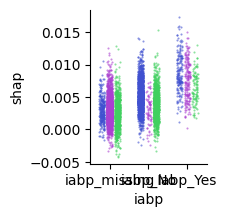

In [ ]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(1.5, 2))
# fig, ax = plt.subplots(figsize=(6, 6))

savepath = 'outputs/figure4/dependence_plots'
var = 'iabp'
AE = 'major'
order = ['iabp_missing', 'iabp_No', 'iabp_Yes']
collections = []

X = Xtest.filter(regex=var+'_')
var_embedded = X.columns.tolist()

X[var] = X.idxmax(axis=1).str.replace('var'+'_', '')#.value_counts()
X = X.reset_index(drop=True)
X['shap'] = retro['shap_values_dfs'][AE][var_embedded].sum(axis=1)
strip1 = sns.stripplot(data=X, x=var, y='shap', jitter=0.07,color="#4051D0BE", 
                       alpha=0.6, size=1.5, ax=ax,order = order)
collections.append(strip1.collections[-1])
collections.append(strip1.collections[-2])
collections.append(strip1.collections[-3])

X = Xpros.filter(regex=var+'_')
var_embedded = X.columns.tolist()
X[var] = X.idxmax(axis=1).str.replace('var'+'_', '')#.value_counts()
X = X.reset_index(drop=True)
X['shap'] = pro['shap_values_dfs'][AE][var_embedded].sum(axis=1)
strip2 = sns.stripplot(data=X, x=var, y='shap', jitter=0.07,color="#AA40D0BD", alpha=0.6, size=1.5, ax=ax)
collections.append(strip2.collections[-1])
collections.append(strip2.collections[-2])
collections.append(strip2.collections[-3])

X = X_bwh.filter(regex=var+'_')
var_embedded = X.columns.tolist()
X[var] = X.idxmax(axis=1).str.replace('var'+'_', '')#.value_counts()
X = X.reset_index(drop=True)
X['shap'] = bwh['shap_values_dfs'][AE][var_embedded].sum(axis=1)
strip3 = sns.stripplot(data=X, x=var, y='shap', jitter=0.07 ,color="#40D05FBC", alpha=0.6, size=1.5, ax=ax)
collections.append(strip3.collections[-1])
collections.append(strip3.collections[-2])
collections.append(strip3.collections[-3])

# Shift collections:
shifts = [-0.2,-0.2,-0.2, 0.0,0.0,0.0, 0.2, 0.2, 0.2]  # For each plot
# Apply shifts
for coll, shift in zip(collections, shifts):
    offsets = coll.get_offsets()
    offsets[:, 0] += shift
    coll.set_offsets(offsets)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.savefig(savepath+'/'+AE+'_'+var+'.jpg', format='jpg', dpi=300,bbox_inches='tight')


/var/folders/d1/3bngkt6j06z8c88jx3kxc22w0000gn/T/ipykernel_43617/97131029.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[var] = X.idxmax(axis=1).str.replace('var'+'_', '')#.value_counts()
/var/folders/d1/3bngkt6j06z8c88jx3kxc22w0000gn/T/ipykernel_43617/97131029.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[var] = X.idxmax(axis=1).str.replace('var'+'_', '')#.value_counts()
/var/folders/d1/3bngkt6j06z8c88jx3kxc22w0000gn/T/ipykernel_43617/97131029.py:35: SettingWithCopyWarning: 
A value is try

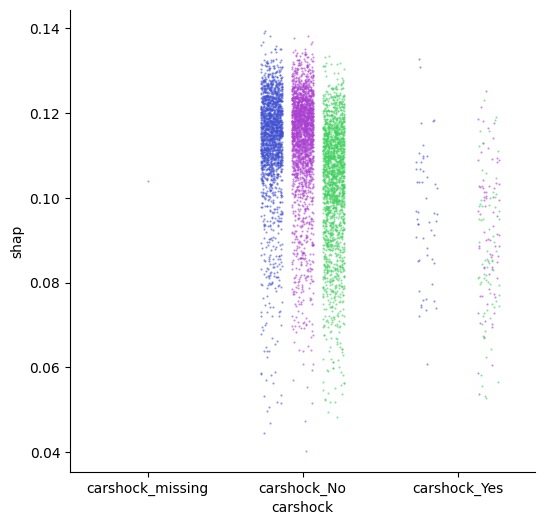

In [ ]:
import seaborn as sns
# fig, ax = plt.subplots(figsize=(1.5, 2))
fig, ax = plt.subplots(figsize=(6, 6))

savepath = 'outputs/figure4/dependence_plots'
var = 'carshock'
AE = 'major'
order = ['carshock_missing','carshock_No', 'carshock_Yes']
collections = []

X = Xtest.filter(regex=var+'_')
var_embedded = X.columns.tolist()

X[var] = X.idxmax(axis=1).str.replace('var'+'_', '')#.value_counts()
X = X.reset_index(drop=True)
X['shap'] = retro['shap_values_dfs'][AE][var_embedded].sum(axis=1)
strip1 = sns.stripplot(data=X, x=var, y='shap', jitter=0.07,color="#4051D0BE", 
                       alpha=0.6, size=1.5, ax=ax,order = order)
collections.append(strip1.collections[-1])
collections.append(strip1.collections[-2])
collections.append(strip1.collections[-3])

X = Xpros.filter(regex=var+'_')
var_embedded = X.columns.tolist()
X[var] = X.idxmax(axis=1).str.replace('var'+'_', '')#.value_counts()
X = X.reset_index(drop=True)
X['shap'] = pro['shap_values_dfs'][AE][var_embedded].sum(axis=1)
strip2 = sns.stripplot(data=X, x=var, y='shap', jitter=0.07,color="#AA40D0BD", alpha=0.6, size=1.5, ax=ax)
collections.append(strip2.collections[-1])
collections.append(strip2.collections[-2])
collections.append(strip2.collections[-3])

X = X_bwh.filter(regex=var+'_')
var_embedded = X.columns.tolist()
X[var] = X.idxmax(axis=1).str.replace('var'+'_', '')#.value_counts()
X = X.reset_index(drop=True)
X['shap'] = bwh['shap_values_dfs'][AE][var_embedded].sum(axis=1)
strip3 = sns.stripplot(data=X, x=var, y='shap', jitter=0.07 ,color="#40D05FBC", alpha=0.6, size=1.5, ax=ax)
collections.append(strip3.collections[-1])
collections.append(strip3.collections[-2])
collections.append(strip3.collections[-3])

# Shift collections:
shifts = [-0.2,-0.2,-0.2, 0.0,0.0,0.0, 0.2, 0.2, 0.2]  # For each plot
# Apply shifts
for coll, shift in zip(collections, shifts):
    offsets = coll.get_offsets()
    offsets[:, 0] += shift
    coll.set_offsets(offsets)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.savefig(savepath+'/'+AE+'_'+var+'.jpg', format='jpg', dpi=300,bbox_inches='tight')
